# 04 - XGBoost

Run all cells in order. A sequence of boosted trees that optimizes a multiclass objective. The 2025 evaluation cohort was previously inspected. Training is performed twice and may take several minutes.

### How to run a cell
Click inside a cell, then click the **Run (▶)** button in the Jupyter toolbar. You can also press **Shift + Enter**. Start with the first cell and run the cells in order; later cells use variables created by earlier ones.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, f1_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits
DATA = Path('data/final_matched_2021_2025.csv.gz')
assert DATA.exists(), 'Start Jupyter in the project folder.'
LABELS = np.array(['Fatal','Serious','Slight'])
from xgboost import XGBClassifier

## 1. Load the finalized dataset and split by year

In [2]:
data = pd.read_csv(DATA, dtype={'collision_index': str}, float_precision='round_trip')
train = data[data.year.isin([2021,2022,2023])].copy()
validation = data[data.year == 2024].copy()
test = data[data.year == 2025].copy()
assert (len(train),len(validation),len(test)) == (60945,19176,19062)
display(pd.DataFrame({'group':['Training (2021-23)','Validation (2024)','Evaluation (2025)'],'rows':[len(train),len(validation),len(test)]}))
display(test.severity.value_counts().reindex(['Slight','Serious','Fatal']).to_frame('2025 collisions'))

,group,rows
0,Training (2021-23),60945
1,Validation (2024),19176
2,Evaluation (2025),19062


,2025 collisions
severity,
Slight,14639
Serious,4219
Fatal,204


## 2. Select the seven feature groups

ID, year, count-point ID and severity are metadata or target, never predictors.

In [3]:
categorical = ['road_type','weather_conditions','road_surface_conditions']
numeric = ['speed_limit','time_sin','time_cos','aadf_motor_vehicles_per_day',
           'time_sin_2','time_cos_2','time_sin_3','time_cos_3',
           'vehicle_composition_cycle','vehicle_composition_motorcycle',
           'vehicle_composition_car_taxi','vehicle_composition_bus',
           'vehicle_composition_goods','vehicle_composition_other']
vehicle_flags = sorted(c for c in data.columns if c.startswith('vehicle_type_'))
features = categorical + numeric + vehicle_flags
assert set(features) == set(data.columns) - {'collision_index','severity','year','count_point_id'}
print(f'{len(features)} columns represent the seven input groups:')
print(features)

40 columns represent the seven input groups:
['road_type', 'weather_conditions', 'road_surface_conditions', 'speed_limit', 'time_sin', 'time_cos', 'aadf_motor_vehicles_per_day', 'time_sin_2', 'time_cos_2', 'time_sin_3', 'time_cos_3', 'vehicle_composition_cycle', 'vehicle_composition_motorcycle', 'vehicle_composition_car_taxi', 'vehicle_composition_bus', 'vehicle_composition_goods', 'vehicle_composition_other', 'vehicle_type_1', 'vehicle_type_10', 'vehicle_type_11', 'vehicle_type_16', 'vehicle_type_17', 'vehicle_type_18', 'vehicle_type_19', 'vehicle_type_2', 'vehicle_type_20', 'vehicle_type_21', 'vehicle_type_22', 'vehicle_type_23', 'vehicle_type_3', 'vehicle_type_33', 'vehicle_type_4', 'vehicle_type_5', 'vehicle_type_8', 'vehicle_type_9', 'vehicle_type_90', 'vehicle_type_97', 'vehicle_type_98', 'vehicle_type_99', 'vehicle_type_missing']


## 3. Prepare the input columns

The model needs numbers. We fill missing category values, then turn categories into columns using one-hot encoding. We fill missing numeric values with the training median and add missing-value indicators. The vehicle-type columns are already numeric, so they pass through unchanged.

The pipeline learns these values from training data during `fit()`; it does not learn them from the evaluation data.

In [4]:
categorical_pipeline = Pipeline([
    ('missing', SimpleImputer(strategy='constant', fill_value=-1)),
    ('one_hot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
preprocessor = ColumnTransformer([
    ('categories', categorical_pipeline, categorical),
    ('numeric', SimpleImputer(strategy='median', add_indicator=True), numeric),
    ('vehicles', 'passthrough', vehicle_flags)
])
print('Preprocessing is ready. It will learn from the training data when the model is fitted.')

Preprocessing is ready. It will learn from the training data when the model is fitted.


## 4. Define the model

These are the fixed settings used for the earlier comparison; this notebook does not repeat the previous hyperparameter search.

In [5]:
model = Pipeline([('prepare', preprocessor), ('model', XGBClassifier(n_estimators=250, max_depth=5, learning_rate=0.05, min_child_weight=10, subsample=0.85, colsample_bytree=0.85, reg_lambda=1.0, objective='multi:softprob', num_class=3, tree_method='hist', random_state=42, n_jobs=2))])
print('Model is ready. The next cell trains it.')

Model is ready. The next cell trains it.


## 5. Train on 2021-2023

Labels are encoded Fatal = 0, Serious = 1, Slight = 2. This configuration does not use class-specific training weights.

In [6]:
y_train = pd.Categorical(train.severity, categories=LABELS).codes
assert set(y_train) == {0,1,2}
# Limit CPU threads to keep the demo manageable.
with threadpool_limits(limits=2):
    model.fit(train[features], y_train)
    validation_probabilities = model.predict_proba(validation[features])
print('Training complete:', validation_probabilities.shape)

Training complete: (19176, 3)


## 6. Choose the decision weights using 2024

We try a few weights for Serious and Fatal predictions. For each pair, we calculate macro F1 on the validation data and keep the best pair. Slight always has weight 1. The adjusted scores help choose a class; they are not calibrated probabilities.

In [7]:
best_score = -1

for serious_weight in [0.75, 1, 1.25, 1.5, 2, 3]:
    for fatal_weight in [1, 2, 4, 6, 8, 12]:
        weights = np.array([fatal_weight, serious_weight, 1])
        predictions = LABELS[(validation_probabilities * weights).argmax(axis=1)]
        score = f1_score(validation.severity, predictions, labels=LABELS,
                         average='macro', zero_division=0)

        if score > best_score:
            best_score = score
            decision_weights = weights

print('Best validation macro F1:', round(best_score, 4))
print('Weights for Fatal, Serious, Slight:', decision_weights)

Best validation macro F1: 0.4483
Weights for Fatal, Serious, Slight: [12  3  1]


## 7. Train again and evaluate on 2025

Now that the weights are chosen, we train the same model on 2021-2024. We keep the weights fixed and use the 2025 rows to calculate the results. The 2025 rows were already inspected in earlier work, so they are not a fresh final test.

In [8]:
development = pd.concat([train, validation], ignore_index=True)
y_development = pd.Categorical(development.severity, categories=LABELS).codes
# Limit CPU threads to keep the demo manageable.
with threadpool_limits(limits=2):
    model.fit(development[features], y_development)
    test_probabilities = model.predict_proba(test[features])
print('Evaluation rows:', len(test))

Evaluation rows: 19062


2025 accuracy: 68.51%
2025 macro F1: 0.4285


              precision    recall  f1-score   support

      Slight       0.82      0.77      0.80     14639
     Serious       0.35      0.42      0.38      4219
       Fatal       0.10      0.13      0.11       204

    accuracy                           0.69     19062
   macro avg       0.42      0.44      0.43     19062
weighted avg       0.71      0.69      0.70     19062



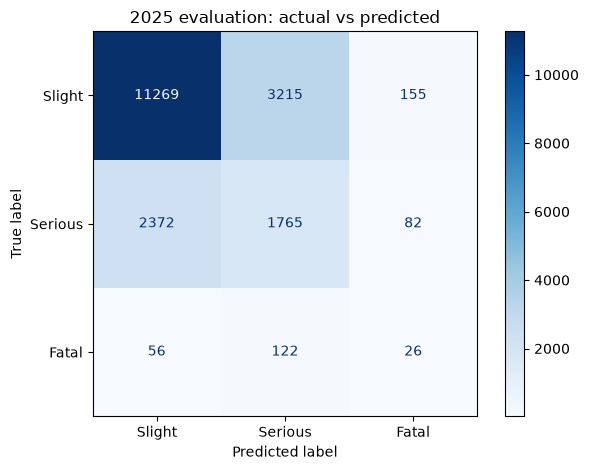

In [9]:
predicted = LABELS[(test_probabilities * decision_weights).argmax(axis=1)]
print('2025 accuracy:', f'{accuracy_score(test.severity, predicted):.2%}')
print('2025 macro F1:', f'{f1_score(test.severity, predicted, labels=LABELS, average="macro", zero_division=0):.4f}')
print(classification_report(test.severity, predicted, labels=['Slight','Serious','Fatal'], zero_division=0))
ConfusionMatrixDisplay.from_predictions(test.severity, predicted, labels=['Slight','Serious','Fatal'], cmap='Blues', values_format='d')
plt.title('2025 evaluation: actual vs predicted'); plt.tight_layout(); plt.show()

The recorded accuracy for this configuration was **68.51%**. Inspect any differences rather than altering the results. Accuracy alone does not establish good Serious or Fatal detection.

## 8. Final comparison

All three models use the same evaluation rows and full 2021 data.

In [10]:
comparison = pd.read_csv('results/final_model_comparison.csv')
display(comparison)
print('Always predicting Slight would score', f'{(test.severity == "Slight").mean():.2%}', 'accuracy and miss all Serious and Fatal crashes.')

,Model,Accuracy (%),Slight recall (%),Serious recall (%),Fatal recall (%),Macro F1
0,Logistic Regression,70.60,82.89,30.79,12.25,0.4172
1,Random Forest,70.19,81.58,33.02,22.06,0.4308
2,XGBoost,68.51,76.98,41.83,12.75,0.4285


Always predicting Slight would score 76.80% accuracy and miss all Serious and Fatal crashes.


## Questions to be ready for

- Why can accuracy be high while Fatal recall is low?
- Why select multipliers on 2024 instead of 2025?
- Is AADF actual traffic density?
- Are vehicle types known before a collision?
- Why are adjusted scores not calibrated probabilities?